# E-Ticaret Oturum Analizi
### Ziyaretçi Davranışlarından Satın Alma Tahmini

**Hazırlayan:** Damla Karaman

## Problem ve amaç
Bir e-ticaret sitesindeki ziyaretçinin gezinme davranışlarını kullanarak,
oturumun satın almayla sonuçlanıp sonuçlanmadığını tahmin etmek.

Bu çalışma, satın almayla ilişkili davranışları inceleyen ve geçmiş
oturum özetleri üzerinde çalışan bir sınıflandırma prototipidir.

## Hedef değişken
Revenue:
- False: Satın alma gerçekleşmedi.
- True: Satın alma gerçekleşti.

## Yöntem
Önce çoğunluk sınıfını tahmin eden bir referans yöntem
(DummyClassifier), ardından bir karar ağacı (DecisionTreeClassifier)
kullanılacaktır.

## Veri kaynağı
Online Shoppers Purchasing Intention Dataset — UCI.
Kaggle: https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset

## Proje kararları ve rapor notları
- Revenue hedef değişkendir; model girdilerine dahil edilmeyecektir.
- PageValues, hesaplanmasında işlem değerleriyle ilişkili bilgi
  kullanıldığı için ilk modelden çıkarılacaktır. Bu karar, doğrulanmış
  veri sızıntısı bulgusu olarak sunulmayacaktır.
- Sınıf dağılımı incelenecek; accuracy yanında precision, recall ve F1
  raporlanacaktır.
- Ön işleme yalnızca eğitim verisinden öğrenilecektir.
- Model ayarları eğitim verisi içinde seçilecek; test verisi son
  değerlendirme için ayrılacaktır.
- Tamamlanmış oturum özetleriyle çalışıldığı için gerçek zamanlı
  tahmin performansı iddia edilmeyecektir.
- Model sonuçları, indirim veya kampanyanın nedensel etkisini göstermez.
- Bulgular ve başarı değerleri kod çıktıları alındıktan sonra yazılacaktır.

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from pathlib import Path
import hashlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Drive'daki klasör adını ekran görüntüsüne göre kullanıyoruz.
PROJE_KLASORU = Path("/content/drive/MyDrive/BasitlestirilmisPy")
VERI_DOSYASI = PROJE_KLASORU / "online_shoppers_intention.csv"
CIKTI_KLASORU = PROJE_KLASORU / "ciktilar"

if not VERI_DOSYASI.is_file():
    raise FileNotFoundError(
        f"CSV bulunamadı: {VERI_DOSYASI}\n"
        "Drive bağlantısını, klasör adını ve CSV dosya adını kontrol et."
    )

CIKTI_KLASORU.mkdir(parents=True, exist_ok=True)

print("CSV bulundu:", VERI_DOSYASI.name)
print("Çıktı klasörü hazır:", CIKTI_KLASORU)
print("Pandas sürümü:", pd.__version__)

CSV bulundu: online_shoppers_intention.csv
Çıktı klasörü hazır: /content/drive/MyDrive/BasitlestirilmisPy/ciktilar
Pandas sürümü: 2.2.3


In [3]:
# Ham veriyi koruyor, inceleme için ayrı bir kopya oluşturuyoruz.
df_ham = pd.read_csv(VERI_DOSYASI)
df = df_ham.copy()

# Aynı veri dosyasını kullandığımızı kontrol edebilmek için parmak izi.
veri_sha256 = hashlib.sha256(VERI_DOSYASI.read_bytes()).hexdigest()

print(f"Satır sayısı: {df.shape[0]:,}")
print(f"Sütun sayısı: {df.shape[1]}")
print("Veri dosyası SHA-256:", veri_sha256)

display(df.head())

# Veri kaynağı bilgilerini Drive'a kaydet.
kaynak_notu = (
    "Veri seti: Online Shoppers Purchasing Intention Dataset\n"
    "Asıl kaynak: UCI Machine Learning Repository\n"
    "Kaggle: https://www.kaggle.com/datasets/imakash3011/"
    "online-shoppers-purchasing-intention-dataset\n"
    f"Dosya: {VERI_DOSYASI.name}\n"
    f"Boyut: {df.shape[0]} satır, {df.shape[1]} sütun\n"
    f"SHA-256: {veri_sha256}\n"
)

(CIKTI_KLASORU / "veri_kaynagi.txt").write_text(
    kaynak_notu, encoding="utf-8"
)

Satır sayısı: 12,330
Sütun sayısı: 18
Veri dosyası SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


338

In [4]:
if "Revenue" not in df.columns:
    raise ValueError("Revenue sütunu bulunamadı.")

if df["Revenue"].isna().any():
    raise ValueError("Hedef sütununda eksik değer var; incelemeliyiz.")

print("Revenue veri tipi:", df["Revenue"].dtype)
print("Revenue değerleri:", df["Revenue"].unique())

hedef_ozeti = df["Revenue"].value_counts(dropna=False).to_frame(
    name="oturum_sayisi"
)
hedef_ozeti["oran_yuzde"] = (
    hedef_ozeti["oturum_sayisi"] / len(df) * 100
).round(2)

display(hedef_ozeti)

hedef_ozeti.to_csv(
    CIKTI_KLASORU / "hedef_dagilimi.csv",
    encoding="utf-8-sig",
    index_label="Revenue"
)

Revenue veri tipi: bool
Revenue değerleri: [False  True]


,oturum_sayisi,oran_yuzde
Revenue,,
False,10422,84.53
True,1908,15.47


In [5]:
print("SÜTUNLAR VE VERİ TİPLERİ")
df.info()

kalite_ozeti = pd.DataFrame({
    "veri_tipi": df.dtypes.astype(str),
    "eksik_deger": df.isna().sum(),
    "benzersiz_deger": df.nunique(dropna=False)
})

display(kalite_ozeti)

# Sayısal sütunlarda negatif ve sonsuz değer kontrolü.
sayisal_veri = df.select_dtypes(include="number")

sayisal_kontrol = pd.DataFrame({
    "minimum": sayisal_veri.min(),
    "maksimum": sayisal_veri.max(),
    "negatif_deger": (sayisal_veri < 0).sum(),
    "sonsuz_deger": np.isinf(sayisal_veri).sum()
})

display(sayisal_kontrol)

print("Toplam eksik hücre:", int(df.isna().sum().sum()))
print("Tam satır tekrar sayısı:", int(df.duplicated().sum()))

# Aynı girdilere sahip kayıtların hedefleri farklı mı?
girdi_sutunlari = df.columns.drop("Revenue").tolist()

celiskili_gruplar = (
    df.groupby(girdi_sutunlari, dropna=False)["Revenue"]
    .nunique()
    .gt(1)
    .sum()
)

print("Aynı girdilere rağmen farklı hedef içeren grup:", int(celiskili_gruplar))

kalite_ozeti.to_csv(
    CIKTI_KLASORU / "veri_kalite_ozeti.csv",
    encoding="utf-8-sig",
    index_label="sutun"
)

sayisal_kontrol.to_csv(
    CIKTI_KLASORU / "sayisal_deger_kontrolu.csv",
    encoding="utf-8-sig",
    index_label="sutun"
)

SÜTUNLAR VE VERİ TİPLERİ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 1

,veri_tipi,eksik_deger,benzersiz_deger
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


,minimum,maksimum,negatif_deger,sonsuz_deger
Administrative,0.0,27.000000,0,0
Administrative_Duration,0.0,3398.750000,0,0
Informational,0.0,24.000000,0,0
Informational_Duration,0.0,2549.375000,0,0
ProductRelated,0.0,705.000000,0,0
ProductRelated_Duration,0.0,63973.522230,0,0
BounceRates,0.0,0.200000,0,0
ExitRates,0.0,0.200000,0,0
PageValues,0.0,361.763742,0,0
SpecialDay,0.0,1.000000,0,0


Toplam eksik hücre: 0
Tam satır tekrar sayısı: 125
Aynı girdilere rağmen farklı hedef içeren grup: 0


In [6]:
# Ham veri korunur. Tekilleştirilmiş veri ayrı bir değişkende tutulur.
df_temiz = df.drop_duplicates().copy()

temizleme_ozeti = pd.DataFrame({
    "islem": [
        "Başlangıç satır sayısı",
        "Çıkarılan tam tekrar sayısı",
        "Kalan satır sayısı"
    ],
    "deger": [
        len(df),
        len(df) - len(df_temiz),
        len(df_temiz)
    ]
})

display(temizleme_ozeti)

# Sorun varsa sessizce doldurmak veya silmek yerine duruyoruz.
if df_temiz.isna().any().any():
    raise ValueError(
        "Eksik değer bulundu. Model aşamasından önce uygun işlemi seçmeliyiz."
    )

sayisal_temiz = df_temiz.select_dtypes(include="number")

if not np.isfinite(sayisal_temiz.to_numpy()).all():
    raise ValueError("Sonsuz veya geçersiz sayısal değer bulundu.")

if (sayisal_temiz < 0).any().any():
    raise ValueError(
        "Negatif değer bulundu. İlgili sütun ve kayıtları incelemeliyiz."
    )

# Analiz kopyasını Drive'a kaydet.
df_temiz.to_csv(
    CIKTI_KLASORU / "oturumlar_tekillestirilmis.csv",
    index=False,
    encoding="utf-8-sig"
)

temizleme_ozeti.to_csv(
    CIKTI_KLASORU / "temizleme_ozeti.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Kontroller tamamlandı; tekilleştirilmiş veri kaydedildi.")

,islem,deger
0,Başlangıç satır sayısı,12330
1,Çıkarılan tam tekrar sayısı,125
2,Kalan satır sayısı,12205


Kontroller tamamlandı; tekilleştirilmiş veri kaydedildi.


In [7]:
from sklearn.model_selection import train_test_split

# Ana modelde PageValues kullanılmayacak.
ozellikler = [
    sutun for sutun in df_temiz.columns
    if sutun not in ["Revenue", "PageValues"]
]

X = df_temiz[ozellikler].copy()
y = df_temiz["Revenue"].astype(int).copy()

# PageValues çıkarıldıktan sonra da aynı girdiler oluşabilir.
# Bu durumda sıradan rastgele bölme yerine grup bazlı ayrım gerekir.
ayni_girdi_sayisi = int(X.duplicated().sum())
print("Seçilen model girdilerindeki tekrar sayısı:", ayni_girdi_sayisi)

if ayni_girdi_sayisi > 0:
    print(
        "Grup bazlı ayrım gerekiyor. "
        "Bu çıktıyı paylaş; sonraki hücreyi buna göre hazırlayacağız."
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    bolunme_ozeti = pd.DataFrame({
        "veri": ["Eğitim", "Test"],
        "satir_sayisi": [len(X_train), len(X_test)],
        "ozellik_sayisi": [X_train.shape[1], X_test.shape[1]],
        "satin_alma_orani_yuzde": [
            round(y_train.mean() * 100, 2),
            round(y_test.mean() * 100, 2)
        ]
    })

    display(bolunme_ozeti)

    # Analizleri bundan sonra eğitim tarafında yapacağız.
    egitim_df = X_train.copy()
    egitim_df["Revenue"] = y_train

    # Bölünmeyi yeniden takip edebilmek için satır indeksleri kaydedilir.
    bolunme_kaydi = pd.concat([
        pd.DataFrame({
            "kaynak_satir_indeksi": X_train.index,
            "bolum": "egitim"
        }),
        pd.DataFrame({
            "kaynak_satir_indeksi": X_test.index,
            "bolum": "test"
        })
    ], ignore_index=True)

    bolunme_kaydi.to_csv(
        CIKTI_KLASORU / "egitim_test_indeksleri.csv",
        index=False
    )

    bolunme_ozeti.to_csv(
        CIKTI_KLASORU / "egitim_test_ozeti.csv",
        index=False,
        encoding="utf-8-sig"
    )

Seçilen model girdilerindeki tekrar sayısı: 0


,veri,satir_sayisi,ozellik_sayisi,satin_alma_orani_yuzde
0,Eğitim,9764,16,15.63
1,Test,2441,16,15.65


## Veri Kalitesi ve Hazırlama Kararları

- Veri setinde 12.330 satır ve 18 sütun bulunmaktadır.
- Eksik hücre, negatif sayısal değer ve sonsuz değer bulunmamıştır.
- 125 tam tekrar çıkarılmış, 12.205 kayıt korunmuştur.
- Tekilleştirme, tekrar kayıtların eğitim ve test taraflarına
  dağılmasını önlemek için uygulanmıştır. Bu kayıtların kesinlikle
  hatalı olduğu iddia edilmemektedir.
- PageValues ana modelin girdilerinden çıkarılmıştır.
- Seçilen 16 girdi üzerinde tekrar kayıt bulunmamıştır.
- Veriler stratify kullanılarak %80 eğitim ve %20 test olarak ayrılmıştır.
- Eğitimde 9.764, testte 2.441 kayıt vardır.
- Satın alma oranları eğitimde %15,63, testte %15,65'tir.
- Ayrıntılı keşif ve model geliştirme eğitim verisi üzerinde yapılacaktır.

Eğitim verisi boyutu: (9764, 17)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
7556,8,203.6,1,0.0,42,1052.400000,0.0,0.004545,0.0,Nov,2,2,5,2,Returning_Visitor,False,1
11924,0,0.0,0,0.0,30,901.288889,0.0,0.007333,0.0,Dec,2,2,7,2,New_Visitor,False,1
3306,0,0.0,0,0.0,13,421.166667,0.0,0.028205,0.8,May,1,1,1,2,Returning_Visitor,False,0
207,2,40.0,0,0.0,5,558.500000,0.0,0.028571,0.0,Mar,2,2,7,2,New_Visitor,True,0
4460,0,0.0,0,0.0,16,1599.266667,0.0,0.013333,0.0,May,4,2,2,13,Returning_Visitor,False,0


,count,mean,std,min,25%,50%,75%,max
Administrative,9764.0,2.342687,3.349268,0.0,0.000000,1.000000,4.000000,27.00000
Administrative_Duration,9764.0,82.219938,179.502363,0.0,0.000000,9.000000,94.725000,3398.75000
Informational,9764.0,0.510344,1.282728,0.0,0.000000,0.000000,0.000000,24.00000
Informational_Duration,9764.0,34.950623,143.828323,0.0,0.000000,0.000000,0.000000,2549.37500
ProductRelated,9764.0,32.101803,44.817312,0.0,8.000000,18.000000,39.000000,705.00000
ProductRelated_Duration,9764.0,1207.264687,1926.389159,0.0,193.466667,617.000000,1483.650000,63973.52223
BounceRates,9764.0,0.020296,0.045234,0.0,0.000000,0.002857,0.016667,0.20000
ExitRates,9764.0,0.041469,0.046145,0.0,0.014286,0.025000,0.049242,0.20000
SpecialDay,9764.0,0.062351,0.199959,0.0,0.000000,0.000000,0.000000,1.00000
OperatingSystems,9764.0,2.130582,0.909649,1.0,2.000000,2.000000,3.000000,8.00000


,oturum_sayisi,oran_yuzde
Revenue,,
0,8238,84.37
1,1526,15.63


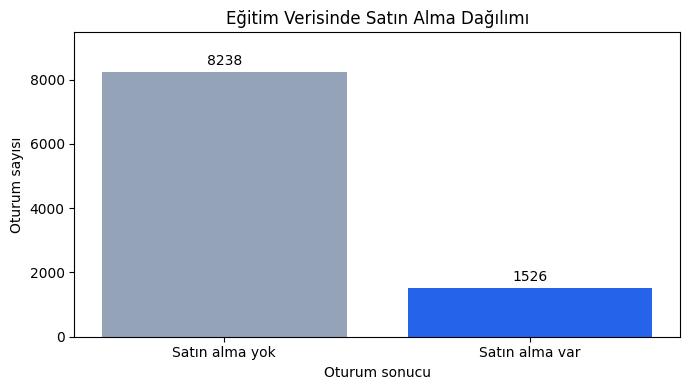

In [8]:
print("Eğitim verisi boyutu:", egitim_df.shape)
display(egitim_df.head())
display(egitim_df.describe().T)

sinif_ozeti = (
    egitim_df["Revenue"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .to_frame("oturum_sayisi")
)

sinif_ozeti["oran_yuzde"] = (
    sinif_ozeti["oturum_sayisi"] / len(egitim_df) * 100
)

display(sinif_ozeti.round(2))

fig, ax = plt.subplots(figsize=(7, 4))

sutunlar = ax.bar(
    ["Satın alma yok", "Satın alma var"],
    sinif_ozeti["oturum_sayisi"],
    color=["#94A3B8", "#2563EB"]
)

ax.bar_label(sutunlar, padding=3)
ax.set_title("Eğitim Verisinde Satın Alma Dağılımı")
ax.set_xlabel("Oturum sonucu")
ax.set_ylabel("Oturum sayısı")
ax.set_ylim(0, sinif_ozeti["oturum_sayisi"].max() * 1.15)

fig.tight_layout()
fig.savefig(
    CIKTI_KLASORU / "01_egitim_sinif_dagilimi.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

,oturum_sayisi,satin_alma_sayisi,satin_alma_orani_yuzde
VisitorType,,,
New_Visitor,1349,325,24.09
Other,68,16,23.53
Returning_Visitor,8347,1185,14.20


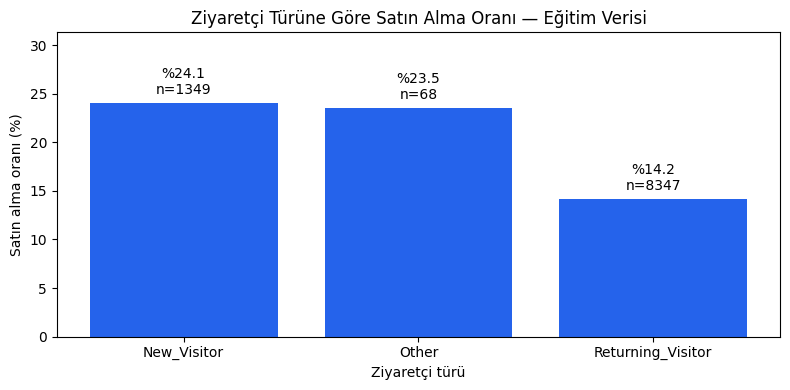

In [9]:
ziyaretci_ozeti = (
    egitim_df.groupby("VisitorType")["Revenue"]
    .agg(oturum_sayisi="size", satin_alma_sayisi="sum",
         satin_alma_orani="mean")
)

ziyaretci_ozeti["satin_alma_orani_yuzde"] = (
    ziyaretci_ozeti["satin_alma_orani"] * 100
)

ziyaretci_ozeti = ziyaretci_ozeti.sort_values(
    "satin_alma_orani_yuzde", ascending=False
)

display(
    ziyaretci_ozeti[
        ["oturum_sayisi", "satin_alma_sayisi", "satin_alma_orani_yuzde"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(8, 4))

sutunlar = ax.bar(
    ziyaretci_ozeti.index,
    ziyaretci_ozeti["satin_alma_orani_yuzde"],
    color="#2563EB"
)

etiketler = [
    f"%{oran:.1f}\nn={adet}"
    for oran, adet in zip(
        ziyaretci_ozeti["satin_alma_orani_yuzde"],
        ziyaretci_ozeti["oturum_sayisi"]
    )
]

ax.bar_label(sutunlar, labels=etiketler, padding=4)
ax.set_title("Ziyaretçi Türüne Göre Satın Alma Oranı — Eğitim Verisi")
ax.set_xlabel("Ziyaretçi türü")
ax.set_ylabel("Satın alma oranı (%)")
ax.set_ylim(
    0, max(ziyaretci_ozeti["satin_alma_orani_yuzde"].max() * 1.3, 10)
)

fig.tight_layout()
fig.savefig(
    CIKTI_KLASORU / "02_ziyaretci_turu_oranlari.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

ziyaretci_ozeti.to_csv(
    CIKTI_KLASORU / "ziyaretci_turu_ozeti.csv",
    encoding="utf-8-sig"
)

,oturum_sayisi,medyan_urun_sayfasi,medyan_urun_suresi_saniye
Revenue,,,
0,8238,16.0,530.81
1,1526,29.0,1122.92


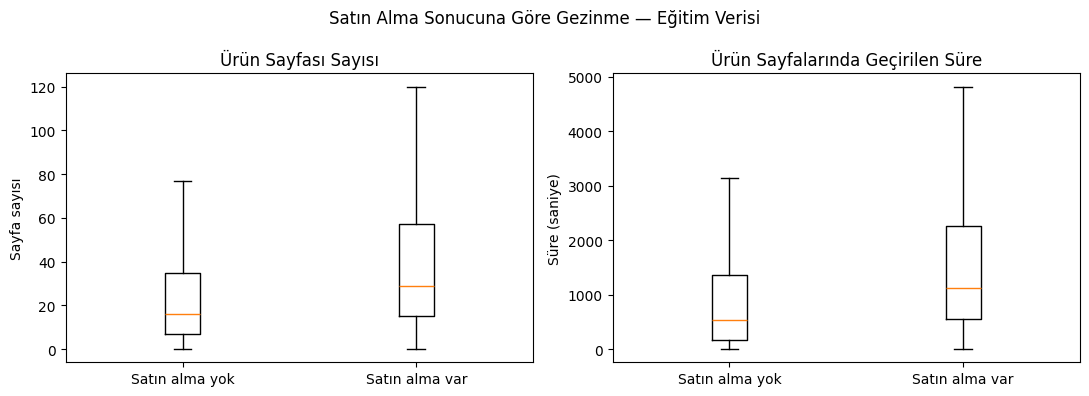

In [10]:
davranis_ozeti = (
    egitim_df.groupby("Revenue")
    .agg(
        oturum_sayisi=("ProductRelated", "size"),
        medyan_urun_sayfasi=("ProductRelated", "median"),
        medyan_urun_suresi_saniye=("ProductRelated_Duration", "median")
    )
)

display(davranis_ozeti.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

incelemeler = [
    ("ProductRelated", "Ürün Sayfası Sayısı", "Sayfa sayısı"),
    ("ProductRelated_Duration", "Ürün Sayfalarında Geçirilen Süre",
     "Süre (saniye)")
]

for ax, (sutun, baslik, eksen) in zip(axes, incelemeler):
    gruplar = [
        egitim_df.loc[egitim_df["Revenue"] == sinif, sutun].to_numpy()
        for sinif in [0, 1]
    ]

    ax.boxplot(gruplar, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Satın alma yok", "Satın alma var"])
    ax.set_title(baslik)
    ax.set_ylabel(eksen)

fig.suptitle("Satın Alma Sonucuna Göre Gezinme — Eğitim Verisi")
fig.tight_layout()
fig.savefig(
    CIKTI_KLASORU / "03_urun_gezinme_davranislari.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

davranis_ozeti.to_csv(
    CIKTI_KLASORU / "urun_davranis_ozeti.csv",
    encoding="utf-8-sig"
)

## Keşifçi Veri Analizi Bulguları

Bu bölümdeki analizler yalnızca eğitim verisi üzerinde yapılmıştır.

1. Eğitim oturumlarının %15,63'ü satın almayla sonuçlanmıştır.
   Bu sınıf dengesizliği nedeniyle model başarısı yalnızca
   accuracy ile değerlendirilmeyecektir.

2. Yeni ziyaretçilerin satın alma oranı %24,09; geri dönen
   ziyaretçilerin oranı %14,20'dir.

3. Other grubunda satın alma oranı %23,53'tür. Ancak bu grup
   yalnızca 68 kayıt içerdiğinden sonuç temkinli yorumlanmalıdır.

4. Satın almayla sonuçlanan oturumlarda medyan ürün sayfası
   sayısı 29, diğer oturumlarda 16'dır.

5. Ürün sayfalarında geçirilen medyan süre satın alanlarda
   1.122,92 saniye, almayanlarda 530,81 saniyedir.

Bu bulgular ilişki göstermektedir; daha uzun gezinmenin veya
ziyaretçi türünün satın almaya neden olduğunu kanıtlamaz.

Kutu grafiklerinde uç noktalar okunabilirlik amacıyla gizlenmiş,
veri setinden çıkarılmamıştır.

In [11]:
# Sayılarla kodlanmış olanlar dahil kategorik değişkenler.
kategorik_sutunlar = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

sayisal_sutunlar = [
    sutun for sutun in X_train.columns
    if sutun not in kategorik_sutunlar
]

# Beklenmeyen sütun veya yanlışlıkla hedef kullanımı kontrolü.
assert set(kategorik_sutunlar).issubset(X_train.columns)
assert "Revenue" not in X_train.columns
assert "PageValues" not in X_train.columns
assert X_train.columns.equals(X_test.columns)

print("Kategorik sütunlar:", kategorik_sutunlar)
print("\nSayısal sütunlar:", sayisal_sutunlar)
print("\nEğitim boyutu:", X_train.shape)
print("Test boyutu:", X_test.shape)

Kategorik sütunlar: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Sayısal sütunlar: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']

Eğitim boyutu: (9764, 16)
Test boyutu: (2441, 16)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Kategorileri ayrı 0/1 sütunlarına dönüştürür.
# Yeni veride bilinmeyen bir kategori gelirse hata vermez.
on_isleme = ColumnTransformer(
    transformers=[
        (
            "kategorik",
            OneHotEncoder(handle_unknown="ignore"),
            kategorik_sutunlar
        ),
        ("sayisal", "passthrough", sayisal_sutunlar)
    ],
    remainder="drop"
)

# Dönüşüm ve model aynı hat içinde çalışır.
agac_pipeline = Pipeline([
    ("on_isleme", on_isleme),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Satın alma sınıfı = 1.
olcumler = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

capraz_dogrulama = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Ön işleme, model hattı ve doğrulama düzeni hazır.")

Ön işleme, model hattı ve doğrulama düzeni hazır.


In [15]:
# Her zaman eğitimde en sık görülen sınıfı tahmin eder.
referans_model = DummyClassifier(strategy="most_frequent")

referans_sonuclari = cross_validate(
    referans_model,
    X_train,
    y_train,
    cv=capraz_dogrulama,
    scoring=olcumler,
    error_score="raise"
)

referans_ozeti = pd.DataFrame({
    "metrik": list(olcumler),
    "ortalama": [
        referans_sonuclari[f"test_{metrik}"].mean()
        for metrik in olcumler
    ],
    "standart_sapma": [
        referans_sonuclari[f"test_{metrik}"].std()
        for metrik in olcumler
    ]
})

display(referans_ozeti.round(4))

,metrik,ortalama,standart_sapma
0,accuracy,0.8437,0.0002
1,precision,0.0000,0.0000
2,recall,0.0000,0.0000
3,f1,0.0000,0.0000


In [14]:
# Küçük ve açıklanabilir bir ayar araması.
parametreler = {
    "model__max_depth": [3, 5, 8],
    "model__min_samples_leaf": [10, 30],
    "model__class_weight": [None, "balanced"]
}

arama = GridSearchCV(
    estimator=agac_pipeline,
    param_grid=parametreler,
    scoring=olcumler,
    refit="f1",
    cv=capraz_dogrulama,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise"
)

arama.fit(X_train, y_train)

# En iyi ayarlarla tüm eğitim verisinde yeniden eğitilmiş hat.
en_iyi_model = arama.best_estimator_

print("Seçilen ayarlar:")
print(arama.best_params_)

print(f"\nEn iyi ortalama doğrulama F1: {arama.best_score_:.4f}")

arama_sonuclari = pd.DataFrame(arama.cv_results_)

gosterilecek_sutunlar = [
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__class_weight",
    "mean_train_f1",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_accuracy"
]

display(
    arama_sonuclari
    .sort_values("rank_test_f1")[gosterilecek_sutunlar]
    .head(10)
    .round(4)
)

# Sonuçları Drive'a kaydet.
arama_sonuclari.to_csv(
    CIKTI_KLASORU / "karar_agaci_capraz_dogrulama.csv",
    index=False,
    encoding="utf-8-sig"
)

referans_ozeti.to_csv(
    CIKTI_KLASORU / "referans_capraz_dogrulama.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nModel eğitimi tamamlandı. Ayrılmış test verisi henüz kullanılmadı.")

Seçilen ayarlar:
{'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 30}

En iyi ortalama doğrulama F1: 0.3848


,param_model__max_depth,param_model__min_samples_leaf,param_model__class_weight,mean_train_f1,mean_test_f1,std_test_f1,mean_test_precision,mean_test_recall,mean_test_accuracy
11,8,30,balanced,0.4409,0.3848,0.0131,0.2630,0.7202,0.6407
9,5,30,balanced,0.4002,0.3839,0.0150,0.2600,0.7424,0.6257
8,5,10,balanced,0.4018,0.3836,0.0143,0.2594,0.7451,0.6238
10,8,10,balanced,0.4491,0.3759,0.0041,0.2561,0.7117,0.6308
6,3,10,balanced,0.3771,0.3708,0.0095,0.2454,0.7602,0.5965
7,3,30,balanced,0.3771,0.3708,0.0095,0.2454,0.7602,0.5965
4,8,10,None,0.3625,0.2095,0.0257,0.3753,0.1468,0.8281
5,8,30,None,0.2521,0.2012,0.0209,0.4759,0.1284,0.8413
2,5,10,None,0.1900,0.1352,0.0388,0.4465,0.0806,0.8406
3,5,30,None,0.1602,0.1176,0.0338,0.4707,0.0675,0.8424



Model eğitimi tamamlandı. Ayrılmış test verisi henüz kullanılmadı.


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Referans yöntem yalnızca eğitim verisiyle eğitilir.
referans_model.fit(X_train, y_train)

referans_test_tahmini = referans_model.predict(X_test)
agac_test_tahmini = en_iyi_model.predict(X_test)

def metrikleri_hesapla(gercek, tahmin):
    return {
        "accuracy": accuracy_score(gercek, tahmin),
        "balanced_accuracy": balanced_accuracy_score(gercek, tahmin),
        "precision": precision_score(gercek, tahmin, zero_division=0),
        "recall": recall_score(gercek, tahmin, zero_division=0),
        "f1": f1_score(gercek, tahmin, zero_division=0)
    }

test_sonuclari = pd.DataFrame({
    "Referans": metrikleri_hesapla(y_test, referans_test_tahmini),
    "Karar ağacı": metrikleri_hesapla(y_test, agac_test_tahmini)
}).T

display(test_sonuclari.round(4))

print("\nKARAR AĞACI SINIFLANDIRMA RAPORU")
print(classification_report(
    y_test,
    agac_test_tahmini,
    labels=[0, 1],
    target_names=["Satın alma yok", "Satın alma var"],
    zero_division=0
))

test_sonuclari.to_csv(
    CIKTI_KLASORU / "model_test_sonuclari.csv",
    encoding="utf-8-sig",
    index_label="model"
)

,accuracy,balanced_accuracy,precision,recall,f1
Referans,0.8435,0.5000,0.0000,0.000,0.0000
Karar ağacı,0.5830,0.6664,0.2431,0.788,0.3716



KARAR AĞACI SINIFLANDIRMA RAPORU
                precision    recall  f1-score   support

Satın alma yok       0.93      0.54      0.69      2059
Satın alma var       0.24      0.79      0.37       382

      accuracy                           0.58      2441
     macro avg       0.59      0.67      0.53      2441
  weighted avg       0.82      0.58      0.64      2441



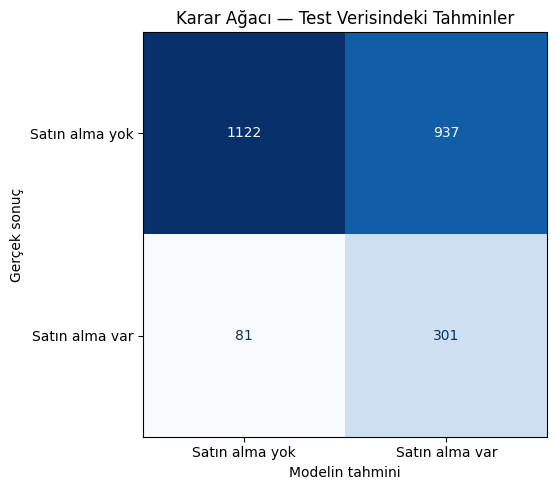

,durum,oturum_sayisi
0,Doğru: satın alma yok,1122
1,"Yanlış alarm: satın almadı, model alır dedi",937
2,"Kaçırılan: satın aldı, model almaz dedi",81
3,Doğru: satın alma var,301


In [17]:
cm = confusion_matrix(
    y_test,
    agac_test_tahmini,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

gosterim = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Satın alma yok", "Satın alma var"]
)

gosterim.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("Karar Ağacı — Test Verisindeki Tahminler")
ax.set_xlabel("Modelin tahmini")
ax.set_ylabel("Gerçek sonuç")

fig.tight_layout()
fig.savefig(
    CIKTI_KLASORU / "04_test_karisiklik_matrisi.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

tn, fp, fn, tp = cm.ravel()

hata_ozeti = pd.DataFrame({
    "durum": [
        "Doğru: satın alma yok",
        "Yanlış alarm: satın almadı, model alır dedi",
        "Kaçırılan: satın aldı, model almaz dedi",
        "Doğru: satın alma var"
    ],
    "oturum_sayisi": [tn, fp, fn, tp]
})

display(hata_ozeti)

hata_ozeti.to_csv(
    CIKTI_KLASORU / "test_hata_ozeti.csv",
    index=False,
    encoding="utf-8-sig"
)

In [18]:
import joblib
import sklearn
import json

test_tahminleri = X_test.copy()
test_tahminleri["gercek_sonuc"] = y_test
test_tahminleri["tahmin"] = agac_test_tahmini
test_tahminleri["dogru_tahmin"] = (
    test_tahminleri["gercek_sonuc"] == test_tahminleri["tahmin"]
)

test_tahminleri.to_csv(
    CIKTI_KLASORU / "test_tahminleri.csv",
    index=True,
    index_label="kaynak_satir_indeksi",
    encoding="utf-8-sig"
)

# Ön işleme ve eğitilmiş model birlikte saklanır.
joblib.dump(
    en_iyi_model,
    CIKTI_KLASORU / "satin_alma_modeli.joblib"
)

model_bilgisi = {
    "model": "DecisionTreeClassifier",
    "secilen_parametreler": arama.best_params_,
    "secim_metrigi": "f1",
    "en_iyi_capraz_dogrulama_f1": float(arama.best_score_),
    "girdi_sutunlari": X_train.columns.tolist(),
    "kategorik_sutunlar": kategorik_sutunlar,
    "sayisal_sutunlar": sayisal_sutunlar,
    "sklearn_surumu": sklearn.__version__,
    "pandas_surumu": pd.__version__,
    "numpy_surumu": np.__version__,
    "veri_sha256": veri_sha256
}

(CIKTI_KLASORU / "model_bilgisi.json").write_text(
    json.dumps(model_bilgisi, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Model, test tahminleri ve model bilgileri Drive'a kaydedildi.")

Model, test tahminleri ve model bilgileri Drive'a kaydedildi.


In [19]:
# Girdi sırası ve kategori seçenekleri yalnızca eğitim verisinden alınır.
girdi_sirasi = X_train.columns.tolist()

kategori_secenekleri = {
    sutun: X_train[sutun].drop_duplicates().tolist()
    for sutun in kategorik_sutunlar
}

tam_sayi_sutunlari = [
    "Administrative", "Informational", "ProductRelated"
]

oran_sutunlari = ["BounceRates", "ExitRates", "SpecialDay"]


def tahmin_et(oturum):
    """Tek bir oturum sözlüğünü doğrular ve sınıf tahmini döndürür."""
    eksik = set(girdi_sirasi) - set(oturum)
    fazla = set(oturum) - set(girdi_sirasi)

    if eksik or fazla:
        raise ValueError(
            f"Eksik sütunlar: {sorted(eksik)}; "
            f"beklenmeyen sütunlar: {sorted(fazla)}"
        )

    veri = pd.DataFrame([oturum], columns=girdi_sirasi)

    for sutun in sayisal_sutunlar:
        deger = pd.to_numeric(veri[sutun], errors="raise").iloc[0]

        if not np.isfinite(deger) or deger < 0:
            raise ValueError(f"{sutun}: sonlu ve negatif olmayan sayı gerekli.")

        if sutun in tam_sayi_sutunlari and deger != int(deger):
            raise ValueError(f"{sutun}: tam sayı gerekli.")

        if sutun in oran_sutunlari and deger > 1:
            raise ValueError(f"{sutun}: 0 ile 1 arasında olmalı.")

        veri[sutun] = float(deger)

    for sutun, secenekler in kategori_secenekleri.items():
        if veri[sutun].iloc[0] not in secenekler:
            raise ValueError(
                f"{sutun}: eğitimde görülen seçeneklerden birini kullan: "
                f"{secenekler}"
            )

    # Pozitif süre varsa ilgili sayfa sayısı sıfır olmamalı.
    for sayac, sure in [
        ("Administrative", "Administrative_Duration"),
        ("Informational", "Informational_Duration"),
        ("ProductRelated", "ProductRelated_Duration")
    ]:
        if veri[sayac].iloc[0] == 0 and veri[sure].iloc[0] > 0:
            raise ValueError(f"{sayac}=0 iken {sure} pozitif olamaz.")

    sinif = int(en_iyi_model.predict(veri)[0])

    return {
        "tahmin_kodu": sinif,
        "tahmin": (
            "Satın alma ile sonuçlanır"
            if sinif == 1
            else "Satın alma ile sonuçlanmaz"
        )
    }


print("Tahmin fonksiyonu hazır.")

Tahmin fonksiyonu hazır.


In [20]:
ortak_bilgiler = {
    "Administrative": 0,
    "Administrative_Duration": 0.0,
    "Informational": 0,
    "Informational_Duration": 0.0,
    "SpecialDay": 0.0,
    "Month": "Nov",
    "OperatingSystems": 2,
    "Browser": 2,
    "Region": 1,
    "TrafficType": 2,
    "VisitorType": "Returning_Visitor",
    "Weekend": False
}

ornek_oturumlar = [
    {
        **ortak_bilgiler,
        "ProductRelated": 2,
        "ProductRelated_Duration": 30.0,
        "BounceRates": 0.10,
        "ExitRates": 0.15
    },
    {
        **ortak_bilgiler,
        "ProductRelated": 20,
        "ProductRelated_Duration": 600.0,
        "BounceRates": 0.01,
        "ExitRates": 0.03
    },
    {
        **ortak_bilgiler,
        "ProductRelated": 50,
        "ProductRelated_Duration": 1800.0,
        "BounceRates": 0.0,
        "ExitRates": 0.01
    }
]

ornek_sonuclari = []

for sira, oturum in enumerate(ornek_oturumlar, start=1):
    sonuc = tahmin_et(oturum)
    ornek_sonuclari.append({
        "ornek": sira,
        **oturum,
        **sonuc
    })

ornek_tablosu = pd.DataFrame(ornek_sonuclari)

display(ornek_tablosu[[
    "ornek",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "tahmin"
]])

# Tam girdi ve tahmin tablosu kaydedilir.
ornek_tablosu.to_csv(
    CIKTI_KLASORU / "uc_yeni_ornek_tahmin.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Bunlar kullanım örnekleridir; gerçek sonuçları bilinmemektedir.")

,ornek,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,tahmin
0,1,2,30.0,0.10,0.15,Satın alma ile sonuçlanmaz
1,2,20,600.0,0.01,0.03,Satın alma ile sonuçlanır
2,3,50,1800.0,0.00,0.01,Satın alma ile sonuçlanır


Bunlar kullanım örnekleridir; gerçek sonuçları bilinmemektedir.


In [21]:
def kullanicidan_oturum_al():
    oturum = {}

    print("E-TİCARET OTURUM ANALİZİ")
    print("Tamamlanmış bir oturumun bilgilerini gir.")
    print("Süreler saniye, oranlar 0–1 aralığındadır.\n")

    for sutun in girdi_sirasi:
        while True:
            try:
                if sutun in kategorik_sutunlar:
                    secenekler = kategori_secenekleri[sutun]

                    print(f"\n{sutun} seçenekleri:")
                    for numara, secenek in enumerate(secenekler, start=1):
                        print(f"  {numara}: {secenek}")

                    secim = int(input("Seçim numarası: "))

                    if not 1 <= secim <= len(secenekler):
                        raise ValueError("Listeden geçerli bir numara seç.")

                    oturum[sutun] = secenekler[secim - 1]

                else:
                    giris = input(f"{sutun}: ").strip().replace(",", ".")
                    deger = float(giris)

                    if not np.isfinite(deger) or deger < 0:
                        raise ValueError("Sonlu ve negatif olmayan sayı gir.")

                    if sutun in tam_sayi_sutunlari and not deger.is_integer():
                        raise ValueError("Sayfa sayısı tam sayı olmalı.")

                    if sutun in oran_sutunlari and deger > 1:
                        raise ValueError("Oran 0 ile 1 arasında olmalı.")

                    oturum[sutun] = (
                        int(deger)
                        if sutun in tam_sayi_sutunlari
                        else deger
                    )

                break

            except ValueError as hata:
                print(f"Geçersiz giriş: {hata}")

    return oturum


def uygulamayi_calistir():
    oturum = kullanicidan_oturum_al()

    try:
        sonuc = tahmin_et(oturum)
    except ValueError as hata:
        print(f"\nOturum bilgileri tutarsız: {hata}")
        print("Hücreyi yeniden çalıştırarak girdileri düzelt.")
        return

    print(f"\nModelin tahmini: {sonuc['tahmin']}.")
    print("Bu sonuç kesin değildir; model yanlış tahmin üretebilir.")

    kayit = pd.DataFrame([{**oturum, **sonuc}])

    kayit.to_csv(
        CIKTI_KLASORU / "son_kullanici_tahmini.csv",
        index=False,
        encoding="utf-8-sig"
    )

    cikti_metni = (
        f"Girdiler:\n{oturum}\n\n"
        f"Modelin tahmini: {sonuc['tahmin']}.\n"
        "Bu sonuç kesin değildir; model yanlış tahmin üretebilir.\n"
    )

    (CIKTI_KLASORU / "ornek_calistirma.txt").write_text(
        cikti_metni,
        encoding="utf-8"
    )

    print("Bu çalıştırmanın girdileri ve sonucu Drive'a kaydedildi.")


# Toplu çalıştırmada uygulama isteğe bağlı açılır.
if input("Mini uygulamayı açmak ister misin? (e/h): ").strip().lower() == "e":
    uygulamayi_calistir()

Mini uygulamayı açmak ister misin? (e/h): e
E-TİCARET OTURUM ANALİZİ
Tamamlanmış bir oturumun bilgilerini gir.
Süreler saniye, oranlar 0–1 aralığındadır.

Administrative: 1
Administrative_Duration: 2
Informational: 3
Informational_Duration: 4
ProductRelated: 5
ProductRelated_Duration: 6
BounceRates: 7
Geçersiz giriş: Oran 0 ile 1 arasında olmalı.
BounceRates: 1
ExitRates: 1
SpecialDay: 1

Month seçenekleri:
  1: Nov
  2: Dec
  3: May
  4: Mar
  5: Oct
  6: Sep
  7: Jul
  8: Feb
  9: Aug
  10: June
Seçim numarası: 4

OperatingSystems seçenekleri:
  1: 2
  2: 1
  3: 4
  4: 3
  5: 8
  6: 5
  7: 6
  8: 7
Seçim numarası: 5

Browser seçenekleri:
  1: 2
  2: 1
  3: 5
  4: 8
  5: 10
  6: 4
  7: 6
  8: 7
  9: 3
  10: 13
  11: 11
  12: 12
  13: 9
Seçim numarası: 4

Region seçenekleri:
  1: 5
  2: 7
  3: 1
  4: 2
  5: 3
  6: 6
  7: 4
  8: 8
  9: 9
Seçim numarası: 8

TrafficType seçenekleri:
  1: 2
  2: 13
  3: 3
  4: 1
  5: 4
  6: 20
  7: 8
  8: 5
  9: 7
  10: 11
  11: 10
  12: 15
  13: 6
  14: 1